In [8]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from simulator import smFRET_simulator_wrapper
from gsl_spline import spline
from priors import generate_spline_fret_prior_from_config
from utils import make_spline_knots

In [9]:
@np.vectorize
def double_well_potential(x, deltaG=4.0, deltax=2.4):
    x = x - 5.0
    x_rel = x / deltax
    if np.abs(x_rel) >= 0 and np.abs(x_rel) <= 0.5:
        g =  -2*x_rel**2
    elif np.abs(x_rel) > 0.5:
        g =  2*(np.abs(x_rel) - 1)**2 - 1
    return g * deltaG

In [10]:
x_min, x_max = 0, 10.0
num_knots = 5
x = np.linspace(x_min, x_max, num_knots + 4) # +4 for boundary nodes
y = double_well_potential(x, deltaG=5) # +4 for boundary nodes
x = x[2:-2]
y = y[2:-2]

In [11]:
def eval_spline(params, N_knots, x_min, x_max, boundary_condition, max_G0, spline_type="cubic"):
    
    
    x_knots, y_knots = make_spline_knots(
        params=params,
        x_min=x_min,
        x_max=x_max,
        num_knots=N_knots,
        max_G0=max_G0,
        boundary_condition=boundary_condition
    )

    _x =  np.linspace(x_min, x_max, 1000)
    _y = spline(x_knots, y_knots, _x, spline_type=spline_type)

    return _x, _y

In [12]:
params = torch.tensor([0.0, *y, 4.0, 10.5, 0.05, 0.05, 0.75, 0.75, 0.9, 0.9, 0.1, 0.1])
#params[2] += 20.0

In [13]:
params[num_knots+1]

tensor(4., dtype=torch.float64)

(-10.0, 1.0)

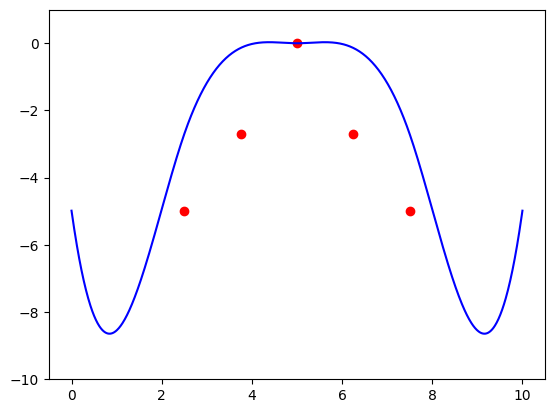

In [14]:
plt.plot(*eval_spline(params, N_knots=num_knots, x_min=x_min, x_max=x_max, boundary_condition='bound', max_G0=50.0, spline_type="cubic"), color='blue')
plt.scatter(x, y, color='red')
plt.ylim(-10, 1)

In [50]:
observation = smFRET_simulator_wrapper(                
    params, 
    dt=5e-4, 
    saving_freq=100, 
    T=5000.0, 
    x_init=(3.0, 7.0),
    x_min=x_min,
    x_max=x_max,
    N_knots=num_knots,
    max_G0=30.0,
    boundary_condition='bound',
    spline_type="steffen"
)

ValueError: only one element tensors can be converted to Python scalars

In [20]:
type(observation)

torch.Tensor

In [21]:
def bin_along_time(x, n_bins=100):
    n = len(x)
    n_per_bin = int(n / n_bins)
    x_binned = np.zeros(n_bins)
    for i in range(n_bins):
        x_binned[i] = np.sum(x[i*n_per_bin:(i+1)*n_per_bin])
    return x_binned

Text(0.5, 0, 'Time')

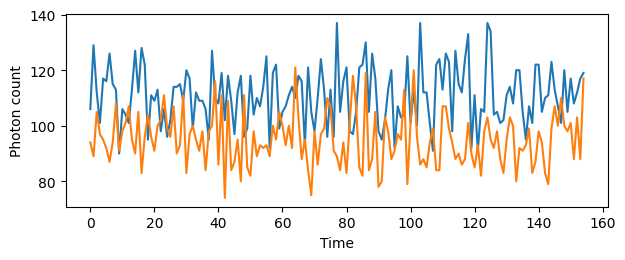

In [174]:
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[ :,0].numpy(), n_bins=155), label="Donor")
plt.plot(bin_along_time(observation[ :,1].numpy(), n_bins=155), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")


In [175]:
from priors import generate_spline_fret_prior_from_config
from utils import eval_spline

In [176]:
prior = generate_spline_fret_prior_from_config("../conf/simulator/default.yaml")

None


In [177]:
params = prior.sample((40,))

(-10.0, 10.0)

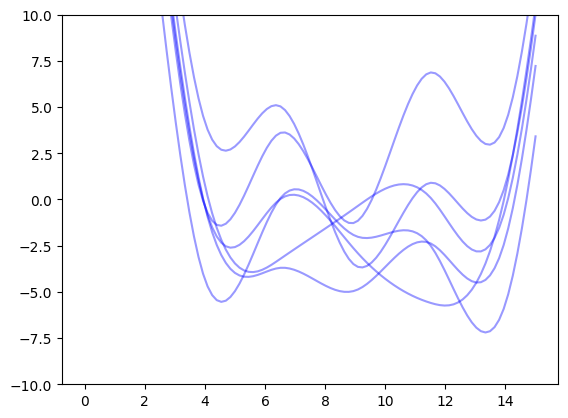

In [179]:
for i in range(6):
    x, y = eval_spline(
        params[i],
        x_eval=np.linspace(0, 15, 100), 
        N_knots=5,
        x_min=4.0, 
        x_max=14.0, 
        boundary_condition='bound', 
        max_G0=30.0, 
        spline_type="cubic"
    )
    plt.plot(x, y, color='blue', alpha=0.4)
plt.ylim(-10, 10)

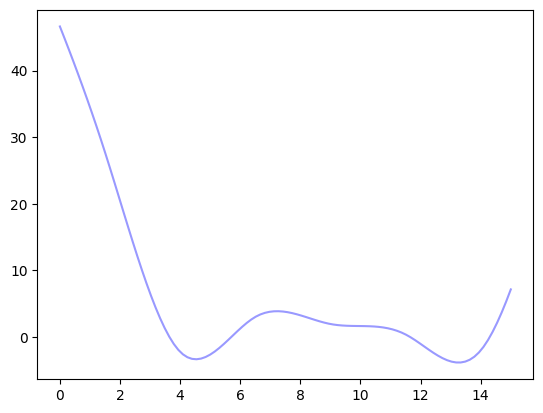

In [181]:
x, y = eval_spline(
    params[23],
    x_eval=np.linspace(0, 15, 100), 
    N_knots=5,
    x_min=4.0, 
    x_max=14.0, 
    boundary_condition='bound', 
    max_G0=30.0, 
    spline_type="cubic"
)
plt.plot(x, y, color='blue', alpha=0.4)

In [188]:
params[23][2+num_knots] = 0.1
observation = smFRET_simulator_wrapper(                
    params[23], 
    dt=5e-5, 
    saving_freq=1000, 
    T=10000.0, 
    x_init=(5.0, 15.0),
    x_min=x_min,
    x_max=x_max,
    N_knots=num_knots,
    max_G0=30.0,
    boundary_condition='bound',
    spline_type="cubic"
)

Text(0.5, 0, 'Time')

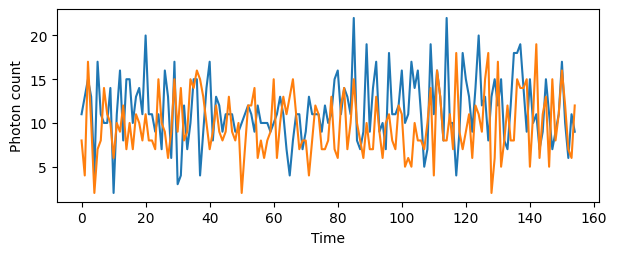

In [189]:
plt.figure(figsize=(7, 2.5))
plt.plot(bin_along_time(observation[ :,0].numpy(), n_bins=155), label="Donor")
plt.plot(bin_along_time(observation[ :,1].numpy(), n_bins=155), label="acceptor")
plt.ylabel("Photon count")
plt.xlabel("Time")